# Aid Request Detection in Disaster Response Messages Using TF-IDF and Sentence-BERT

**Course:** ARTI452 – Natural Language Processing &nbsp;|&nbsp; **Academic year:** 2026–2027, First semester
**Section:** 7FA2 &nbsp;|&nbsp; **Group:** 7 &nbsp;|&nbsp; **Instructor:** Dr. Hayat Alfaghum

| # | Name | ID | Responsibilities |
|---|------|----|------------------|
| 1 | Batool Ashour | 2240004610 | Data cleaning, exploratory analysis |
| 2 | Farah Almujaljel | 2240005623 | Method 1 training and testing |
| 3 | Aryam Hassan | 2240009034 | Method 2 training and testing |

---
### Table of Contents
1. Project Overview & Objectives
2. Environment Setup & Imports
3. Dataset Loading
4. Exploratory Data Analysis (EDA)
5. Data Cleaning & Preprocessing
6. Train / Development / Test Split
7. Method 1: TF-IDF + Logistic Regression
8. Method 2: Sentence-BERT + Logistic Regression
9. Model Evaluation (Accuracy, Macro F1, Confusion Matrix)
10. Error Analysis & Model Comparison
11. Try It: Predict New Messages
12. Conclusion & References

## 1. Project Overview & Objectives

**Task:** Binary text classification of disaster-related messages.

| Input | Output |
|-------|--------|
| A message sent during a disaster | `1` = Request for Aid, `0` = No Request |

**Objectives**
- Build two classifiers that detect aid requests in disaster messages.
- Compare a **traditional** representation (TF-IDF) with a **pretrained** one (Sentence-BERT), using the **same classifier** (Logistic Regression).
- Evaluate both on the **same test set** using **Accuracy** and **Macro F1-score**.

**Experimental question:**
> Which NLP method performs better at detecting aid requests in disaster response messages?

> 💡 Keeping the classifier fixed means any difference in results comes from the *text representation*, which makes the comparison fair.

## 2. Environment Setup & Imports



In [ ]:
import re
import html
import random
import os
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

In [ ]:
# Keep random results consistent each time we run the notebook.
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

## 3. Dataset Loading

**Dataset:** Disaster Response Messages (Figure Eight), publicly available on Kaggle [1].
Contains English disaster-related messages from news, direct messages, and social media, with multiple category labels.



In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sidharth178/disaster-response-messages")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'disaster-response-messages' dataset.
Path to dataset files: /kaggle/input/disaster-response-messages


In [ ]:
# Load the messages and turn category labels into separate columns.
TEXT_COL = "message"
TARGET_COL = "request"
LABEL_NAMES = {0: "No Request", 1: "Request for Aid"}

messages = pd.read_csv(os.path.join(path, "disaster_messages.csv")).drop_duplicates()
categories = pd.read_csv(os.path.join(path, "disaster_categories.csv")).drop_duplicates()

# Split "related-1;request-0;..." into one column per category
split = categories["categories"].str.split(";", expand=True)
split.columns = split.iloc[0].str.split("-").str[0]
split = split.apply(lambda col: col.str.split("-").str[1].astype(int))
categories = pd.concat([categories["id"], split], axis=1)

df = messages.merge(categories, on="id")

In [ ]:
print("Shape:", df.shape)
print("Columns:", list(df.columns))
df.head()

Shape: (26216, 40)
Columns: ['id', 'message', 'original', 'genre', 'related', 'request', 'offer', 'aid_related', 'medical_help', 'medical_products', 'search_and_rescue', 'security', 'military', 'child_alone', 'water', 'food', 'shelter', 'clothing', 'money', 'missing_people', 'refugees', 'death', 'other_aid', 'infrastructure_related', 'transport', 'buildings', 'electricity', 'tools', 'hospitals', 'shops', 'aid_centers', 'other_infrastructure', 'weather_related', 'floods', 'storm', 'fire', 'earthquake', 'cold', 'other_weather', 'direct_report']


,id,message,original,genre,related,request,offer,aid_related,medical_help,medical_products,...,aid_centers,other_infrastructure,weather_related,floods,storm,fire,earthquake,cold,other_weather,direct_report
0,2,Weather update - a cold front from Cuba that c...,Un front froid se retrouve sur Cuba ce matin. ...,direct,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,7,Is the Hurricane over or is it not over,Cyclone nan fini osinon li pa fini,direct,1,0,0,1,0,0,...,0,0,1,0,1,0,0,0,0,0
2,8,Looking for someone but no name,"Patnm, di Maryani relem pou li banm nouvel li ...",direct,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,9,UN reports Leogane 80-90 destroyed. Only Hospi...,UN reports Leogane 80-90 destroyed. Only Hospi...,direct,1,1,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
4,12,"says: west side of Haiti, rest of the country ...",facade ouest d Haiti et le reste du pays aujou...,direct,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## 4. Exploratory Data Analysis (EDA)

This section explores the dataset to better understand its structure and patterns before training the models.


The analysis includes:

1.   Checking the class distribution to see if the dataset is balanced.
2.   Identifying missing values and duplicate messages.
3.   Making sure the labels only contain 0 and 1.
4.  Analyzing message lengths and comparing them between classes.
5.  Comparing message sources (genre) across the two classes.
6.  Examining sample messages to understand the differences between classes.
7.  Identifying the most common words in each class.


,label,count,percent
0,No Request,21742,82.93
1,Request for Aid,4474,17.07


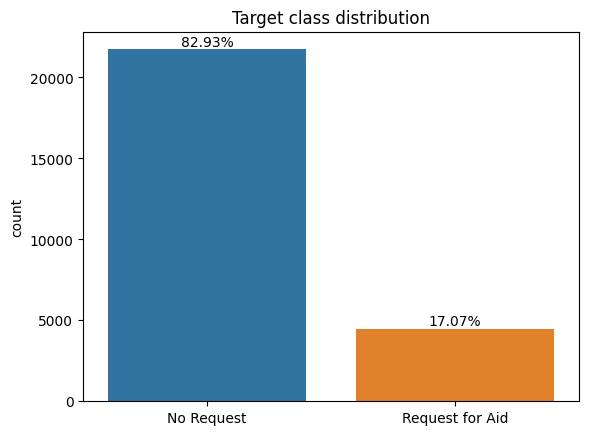

In [ ]:
# See how many messages request aid versus those that do not.
counts = df[TARGET_COL].value_counts(dropna=False).sort_index()
dist = pd.DataFrame({
    "label": [LABEL_NAMES.get(v, f"unexpected: {v}") for v in counts.index],
    "count": counts.values,
    "percent": (counts.values / counts.sum() * 100).round(2),
})
display(dist)

ax = sns.barplot(data=dist, x="label", y="count", hue="label", legend=False)
for p, pct in zip(ax.patches, dist["percent"]):
    ax.annotate(f"{pct}%", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set_title("Target class distribution")
ax.set_xlabel("")
plt.show()

In [ ]:
# Check for missing values, duplicates, and unusual labels.
text = df[TEXT_COL]
print("Missing text:        ", text.isna().sum())
print("Missing target:      ", df[TARGET_COL].isna().sum())
print("Empty/blank text:    ", (text.fillna("").str.strip() == "").sum())
print("Duplicate rows:      ", df.duplicated().sum())
print("Duplicate messages:  ", text.duplicated().sum())

# Same message text but different target labels -> label noise
n_labels = df.groupby(TEXT_COL)[TARGET_COL].nunique()
print("Messages with conflicting labels:", (n_labels > 1).sum())

print("\nUnique target values:", sorted(df[TARGET_COL].dropna().unique().tolist()))

# Any label column that is not strictly binary
num_cols = df.select_dtypes("number").columns.drop("id", errors="ignore")
non_binary = {c: sorted(df[c].dropna().unique().tolist()) for c in num_cols
              if not set(df[c].dropna().unique()) <= {0, 1}}
print("Non-binary label columns:", non_binary if non_binary else "none")

Missing text:         0
Missing target:       0
Empty/blank text:     2
Duplicate rows:       0
Duplicate messages:   39
Messages with conflicting labels: 7

Unique target values: [0, 1]
Non-binary label columns: {'related': [0, 1, 2]}


In [ ]:
# Compare message lengths across the two classes.
# Work on a copy with valid rows only (cleaning itself happens in Section 5)
eda = df.dropna(subset=[TEXT_COL, TARGET_COL]).copy()
eda = eda[eda[TARGET_COL].isin([0, 1])]
eda["label_name"] = eda[TARGET_COL].map(LABEL_NAMES)
eda["n_chars"] = eda[TEXT_COL].str.len()
eda["n_words"] = eda[TEXT_COL].str.split().str.len()

display(eda.groupby("label_name")[["n_words", "n_chars"]].describe().round(1).T)

label_name     No Request  Request for Aid
n_words count     21742.0           4474.0
        mean         24.0             23.0
        std          30.4             39.8
        min           0.0              4.0
        25%          13.0             13.0
        50%          21.0             19.0
        75%          30.0             28.0
        max        1683.0           1686.0
n_chars count     21742.0           4474.0
        mean        148.1            128.4
        std         195.8            255.0
        min           4.0             29.0
        25%          77.0             67.0
        50%         129.0            102.0
        75%         185.0            149.8
        max       10571.0          10818.0

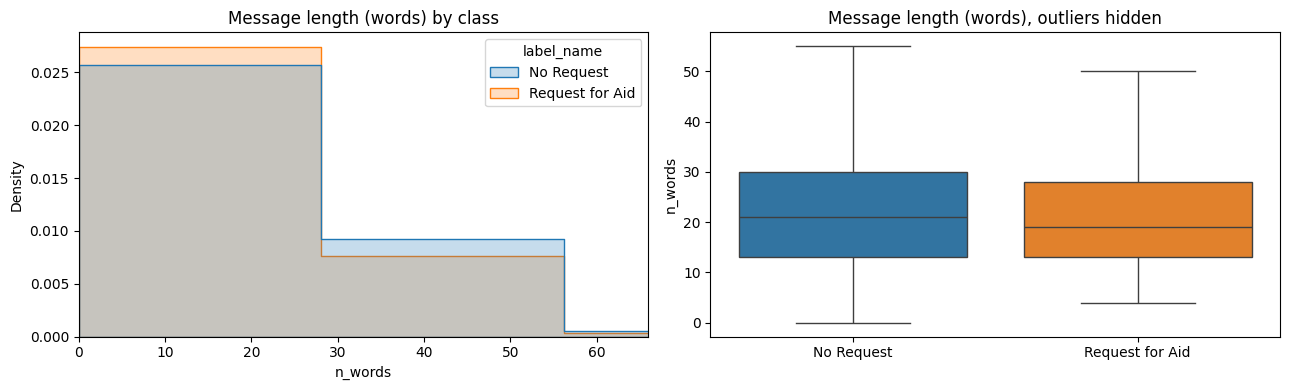

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=eda, x="n_words", hue="label_name", bins=60, stat="density",
             common_norm=False, element="step", ax=axes[0])
axes[0].set_xlim(0, eda["n_words"].quantile(0.99))   # hide extreme outliers
axes[0].set_title("Message length (words) by class")
sns.boxplot(data=eda, x="label_name", y="n_words", hue="label_name", showfliers=False, ax=axes[1])
axes[1].set_title("Message length (words), outliers hidden")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

label_name,No Request,Request for Aid,All
genre,,,
direct,7070,3696,10766
news,12450,604,13054
social,2222,174,2396
All,21742,4474,26216


label_name,No Request,Request for Aid
genre,,
direct,65.67,34.33
news,95.37,4.63
social,92.74,7.26


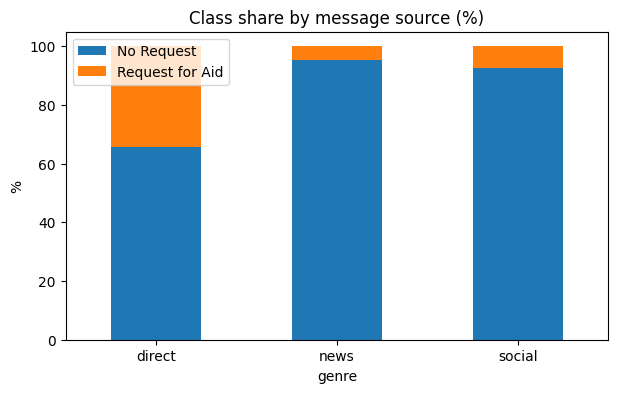

In [ ]:
# Check whether message sources have different label patterns.
if "genre" in eda.columns:
    display(pd.crosstab(eda["genre"], eda["label_name"], margins=True))
    pct = pd.crosstab(eda["genre"], eda["label_name"], normalize="index") * 100
    display(pct.round(2))
    pct.plot(kind="bar", stacked=True, figsize=(7, 4), title="Class share by message source (%)")
    plt.ylabel("%")
    plt.xticks(rotation=0)
    plt.legend(title="")
    plt.show()
else:
    print("No 'genre' column in this version of the dataset.")

In [ ]:
# Read a few examples to understand each class.
for label, name in LABEL_NAMES.items():
    subset = eda.loc[eda[TARGET_COL] == label, TEXT_COL]
    print(f"\n=== {name} ({len(subset)} messages) ===")
    for msg in subset.sample(min(5, len(subset)), random_state=RANDOM_STATE):
        print("-", msg)


=== No Request (21742 messages) ===
- Its three core principles of minimal soil disturbance, permanent soil cover and a crop rotation process that acts as a natural insecticide or herbicide have proven popular in ensuring sustainable and profitable farming here.
- Give me a bit of info about the quake in Haiti. 
- Specifically, we ask that the interim government issue its roadmap for elections without delay so that preparations can begin in earnest.
- I am able and willing to help where I can , whether it be cleaning , food delivery or hand outs , etc .
- The surf charter boats, which are carrying supplies and assessment teams, have been battling 30 knot winds and wild, 3 - 4 metre (10 - 12 foot seas).

=== Request for Aid (4474 messages) ===
- I need a tent and I need plastic sheeting. I can't find them. I am ready to buy once I find somewhere to buy them. 
- I would like to find some informations about these questions that i asked. 
- HELP DIGI, WE ARE SO HUNGRY IN JACMEL, NOT EVERY

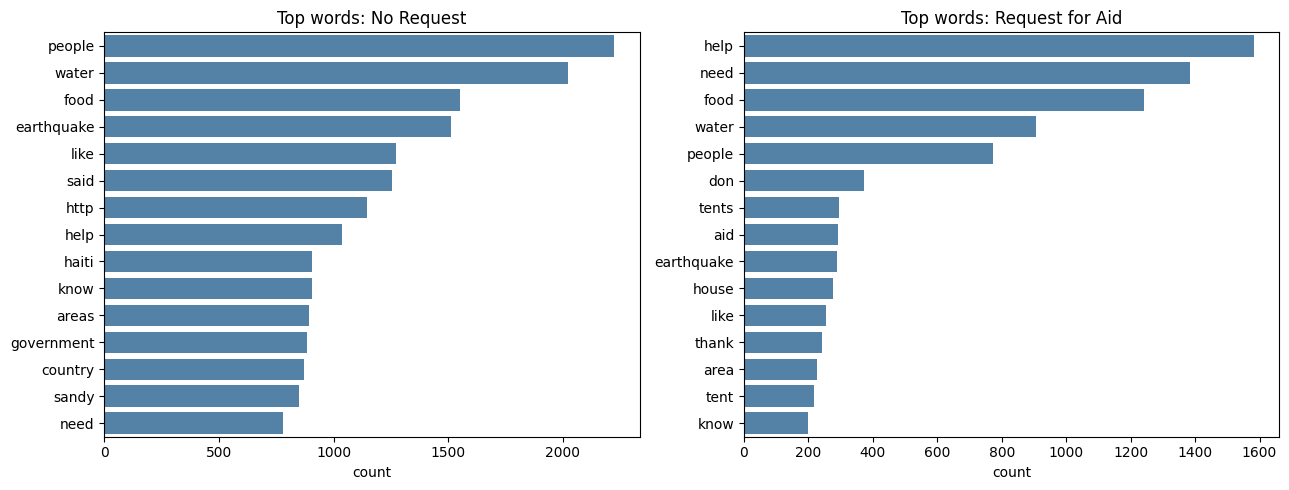

In [ ]:
#most frequent words per class (stopwords removed)
def top_words(texts, n=15):
    tokens = re.findall(r"[a-z]+", " ".join(texts).lower())
    return Counter(t for t in tokens if t not in ENGLISH_STOP_WORDS and len(t) > 2).most_common(n)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (label, name) in zip(axes, LABEL_NAMES.items()):
    words = pd.DataFrame(top_words(eda.loc[eda[TARGET_COL] == label, TEXT_COL]), columns=["word", "count"])
    sns.barplot(data=words, y="word", x="count", ax=ax, color="steelblue")
    ax.set_title(f"Top words: {name}")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

**EDA Observations:**

- **Class Distribution:** The dataset is imbalanced, with 82.93% no requests and 17.07% aid requests.
- **Data Quality:** No missing values, but 2 empty messages, 39 duplicate messages, and 7 messages with conflicting labels were found.
- **Labels:** The target column contains only valid labels (0 and 1).
- **Message Length:** Both classes have similar word counts, but aid requests tend to be slightly shorter.
- **Message Source:** Direct messages have the highest percentage of aid requests (34.33%), compared to news (4.63%) and social messages (7.26%).
- **Preprocessing:** After cleaning, 26,157 messages remained, including 4,458 aid requests.

Overall, the main challenge is the class imbalance, which needs to be considered during model training and evaluation.
























## 5. Data Cleaning & Preprocessing

This section focuses on cleaning and preparing the text data for both models.

The preprocessing includes:

1. Keeping only the necessary columns (text and target).

2. Removing missing, empty, and duplicate messages.

3. Checking that all labels are valid (0 or 1).

4. Creating a clean_text() function to remove URLs, extra spaces, and unnecessary characters.

5. Preparing two versions of the text:

    *   TF-IDF (text_clean): More cleaned and normalized text.
    *   Sentence-BERT (text_light): Lightly cleaned text to preserve the original meaning and context.

This helps prepare the data for each model while keeping the important information in the messages.

In [ ]:
keep_cols = [TEXT_COL, TARGET_COL] + (["genre"] if "genre" in df.columns else [])
df = df[keep_cols].copy()
log = {"start": len(df)}

df = df.dropna(subset=[TEXT_COL, TARGET_COL])
df[TEXT_COL] = df[TEXT_COL].astype(str).str.strip()
df = df[df[TEXT_COL] != ""]
log["after dropping missing/empty"] = len(df)

In [ ]:
# 1) Keep only valid binary labels
df = df[df[TARGET_COL].isin([0, 1])].copy()
df[TARGET_COL] = df[TARGET_COL].astype(int)
log["after removing invalid labels"] = len(df)

# 2) Drop messages that appear with BOTH labels (ambiguous / noisy)
n_labels = df.groupby(TEXT_COL)[TARGET_COL].transform("nunique")
df = df[n_labels == 1]
log["after removing conflicting labels"] = len(df)

# 3) Drop exact duplicate messages (prevents the same text landing in train AND test)
df = df.drop_duplicates(subset=TEXT_COL).reset_index(drop=True)
log["after removing duplicates"] = len(df)

In [ ]:
URL_RE = re.compile(r"(https?\s*:\s*/\s*/\s*\S+|www\.\S+|bit\.ly\S*)", flags=re.IGNORECASE)

def light_clean(text):
    """For Sentence-BERT: keep natural text, only remove noise."""
    text = html.unescape(text)                 # &amp; -> &
    text = URL_RE.sub(" ", text)               # remove URLs
    text = re.sub(r"\s+", " ", text).strip()   # normalize whitespace
    return text

def clean_text(text):
    """For TF-IDF: light clean + lowercase + keep letters only."""
    text = light_clean(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)      # remove punctuation and numbers
    text = re.sub(r"\s+", " ", text).strip()
    return text

In [ ]:
df["text_light"] = df[TEXT_COL].apply(light_clean)   # -> Method 2 (SBERT)
df["text_clean"] = df[TEXT_COL].apply(clean_text)    # -> Method 1 (TF-IDF)

# Drop rows that became empty after cleaning (e.g. messages that were only a URL or numbers)
df = df[df["text_clean"].str.len() > 0].reset_index(drop=True)
log["after cleaning (final)"] = len(df)

print("Cleaning log:")
for step, n in log.items():
    print(f"  {step:<36} {n:>7}")

print("\nFinal class distribution:")
print(df[TARGET_COL].map(LABEL_NAMES).value_counts().to_string())

df[[TEXT_COL, "text_light", "text_clean", TARGET_COL]].sample(5, random_state=RANDOM_STATE)

Cleaning log:
  start                                  26216
  after dropping missing/empty           26214
  after removing invalid labels          26214
  after removing conflicting labels      26198
  after removing duplicates              26161
  after cleaning (final)                 26157

Final class distribution:
request
No Request         21699
Request for Aid     4458


,message,text_light,text_clean,request
10157,Eyewitness Tweets from Haiti http bit.ly 5QVS4...,Eyewitness Tweets from Haiti http 5QVS4c #hait...,eyewitness tweets from haiti http qvs c haiti ...,0
7667,"if we have 55 gourdes on the cell phone, we wi...","if we have 55 gourdes on the cell phone, we wi...",if we have gourdes on the cell phone we will f...,0
17918,"A WHO team visiting Thilafushi, a reclaimed is...","A WHO team visiting Thilafushi, a reclaimed is...",a who team visiting thilafushi a reclaimed isl...,0
24311,22nd May 2015 In continuation to Nepal earthqu...,22nd May 2015 In continuation to Nepal earthqu...,nd may in continuation to nepal earthquake rel...,0
17666,A group of Blackburn Rovers fans recently left...,A group of Blackburn Rovers fans recently left...,a group of blackburn rovers fans recently left...,0


## 6. Train / Development / Test Split

**Purpose:** Separate data for training, tuning, and final evaluation.

| Set | Used for |
|-----|----------|
| **Train** | Fitting the vectorizer / classifier |
| **Development (dev)** | Tuning hyperparameters (e.g., `C`) and the **decision threshold** |
| **Test** | Final, one-time evaluation of both methods |



In [ ]:
# TODO: Split into train and temp (stratified)
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df[TARGET_COL]
)

In [ ]:
# TODO: Split temp into dev and test (stratified)
dev_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df[TARGET_COL]
)

In [ ]:
# TODO: Print the size and class distribution of each set
splits = {
    "Train": train_df,
    "Development": dev_df,
    "Test": test_df
}

for name, data in splits.items():
    print(f"\n{name} Set")
    print("Size:", len(data))
    print("Class Distribution:")
    print(
        data[TARGET_COL]
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
    )


Train Set
Size: 20925
Class Distribution:
request
0    82.96
1    17.04
Name: proportion, dtype: float64

Development Set
Size: 2616
Class Distribution:
request
0    82.95
1    17.05
Name: proportion, dtype: float64

Test Set
Size: 2616
Class Distribution:
request
0    82.95
1    17.05
Name: proportion, dtype: float64


In [ ]:
import os
import shutil

# Create a folder
folder_path = "/content/Dataset_Splits"
os.makedirs(folder_path, exist_ok=True)

# Save the three datasets
train_df.to_csv(f"{folder_path}/train.csv", index=False)
dev_df.to_csv(f"{folder_path}/development.csv", index=False)
test_df.to_csv(f"{folder_path}/test.csv", index=False)

# Compress the folder into a ZIP file
shutil.make_archive(
    "/content/Dataset_Splits",
    "zip",
    "/content",
    "Dataset_Splits"
)

print("Dataset folder created successfully!")

Dataset folder created successfully!


In [ ]:
from google.colab import files

files.download("/content/Dataset_Splits.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Method 1: TF-IDF + Logistic Regression

**Idea:** Represent each message as a sparse vector of weighted word/phrase frequencies. Words frequent in a message but rare across the corpus get higher weight.



In [ ]:
# TODO: Create and fit the TF-IDF vectorizer on training data; transform dev and test
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score, confusion_matrix
import joblib

# rememremember: Fitting the vectorizer on dev/test would leak information — fit on train only.
tfidf_vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2,
                                   max_df=0.95, max_features=100000,
                                   sublinear_tf=True, dtype=np.float32)
X_train_tfidf = tfidf_vectorizer.fit_transform(train_df["text_clean"])
X_dev_tfidf = tfidf_vectorizer.transform(dev_df["text_clean"])
X_test_tfidf = tfidf_vectorizer.transform(test_df["text_clean"])
y_train_tfidf = train_df[TARGET_COL].to_numpy()
y_dev_tfidf = dev_df[TARGET_COL].to_numpy()
y_test_tfidf = test_df[TARGET_COL].to_numpy()
print("Train/dev/test shapes:", X_train_tfidf.shape, X_dev_tfidf.shape, X_test_tfidf.shape)
print("TF-IDF features:", len(tfidf_vectorizer.get_feature_names_out()))

Train/dev/test shapes: (20925, 64404) (2616, 64404) (2616, 64404)
TF-IDF features: 64404


In [ ]:
# TODO: Train Logistic Regression (class_weight='balanced') and tune C on the dev set
tfidf_c_values = [0.01, 0.1, 1, 10, 100]
tfidf_c_results = []
tfidf_best_model = None
tfidf_best_C = None
tfidf_best_dev_f1 = -1
for C in tfidf_c_values:
    candidate = LogisticRegression(C=C, class_weight="balanced",
                                   max_iter=2000, random_state=RANDOM_STATE)
    candidate.fit(X_train_tfidf, y_train_tfidf)
    dev_preds = candidate.predict(X_dev_tfidf)
    score = f1_score(y_dev_tfidf, dev_preds, average="macro", zero_division=0)
    tfidf_c_results.append({"C": C, "Dev Macro F1 at 0.50": score})
    if score > tfidf_best_dev_f1:
        tfidf_best_dev_f1, tfidf_best_C, tfidf_best_model = score, C, candidate
print(pd.DataFrame(tfidf_c_results).to_string(index=False))
print(f"Selected C={tfidf_best_C}; dev Macro F1={tfidf_best_dev_f1:.4f}")

     C  Dev Macro F1 at 0.50
  0.01              0.794745
  0.10              0.801260
  1.00              0.811982
 10.00              0.813876
100.00              0.800689
Selected C=10; dev Macro F1=0.8139


Selected development threshold=0.67
Development Macro F1 after tuning=0.8194


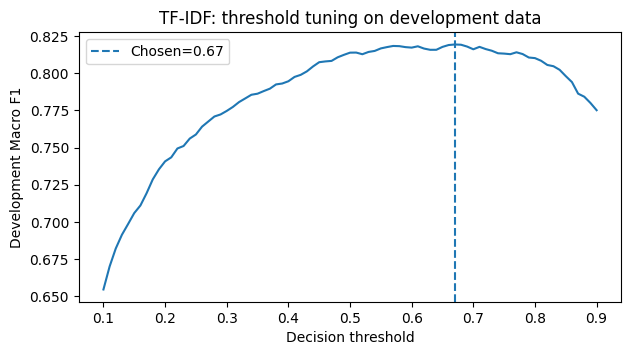

In [ ]:
# TODO: Tune the decision threshold on the dev set (maximize Macro F1)
tfidf_dev_prob = tfidf_best_model.predict_proba(X_dev_tfidf)[:, 1]
tfidf_thresholds = np.round(np.arange(0.10, 0.901, 0.01), 2)
tfidf_threshold_scores = [f1_score(y_dev_tfidf, (tfidf_dev_prob >= t).astype(int),
                                   average="macro", zero_division=0) for t in tfidf_thresholds]
tfidf_peak = max(tfidf_threshold_scores)
tfidf_ties = [float(t) for t, s in zip(tfidf_thresholds, tfidf_threshold_scores)
              if np.isclose(s, tfidf_peak)]
tfidf_best_threshold = min(tfidf_ties, key=lambda t: abs(t - 0.50))
print(f"Selected development threshold={tfidf_best_threshold:.2f}")
print(f"Development Macro F1 after tuning={tfidf_peak:.4f}")
plt.figure(figsize=(7, 3.5))
plt.plot(tfidf_thresholds, tfidf_threshold_scores)
plt.axvline(tfidf_best_threshold, linestyle="--", label=f"Chosen={tfidf_best_threshold:.2f}")
plt.xlabel("Decision threshold"); plt.ylabel("Development Macro F1")
plt.title("TF-IDF: threshold tuning on development data"); plt.legend(); plt.show()

In [ ]:
# TODO: Store the final TF-IDF model, vectorizer, and best threshold
tfidf_artifact = {"vectorizer": tfidf_vectorizer,
                  "classifier": tfidf_best_model,
                  "threshold": tfidf_best_threshold,
                  "chosen_C": tfidf_best_C,
                  "target_labels": LABEL_NAMES}
joblib.dump(tfidf_artifact, "tfidf_logreg_artifact.joblib")
print("Saved tfidf_logreg_artifact.joblib")

Saved tfidf_logreg_artifact.joblib


## 8. Method 2: Sentence-BERT + Logistic Regression

**Idea:** Use a pretrained transformer (`all-MiniLM-L6-v2`) [2] to turn each message into a dense **384-dimensional** embedding that captures meaning, not just exact words.



In [ ]:
# TODO: Load the Sentence-BERT model
from sentence_transformers import SentenceTransformer

model_name = "all-MiniLM-L6-v2"

sbert = SentenceTransformer(model_name)

print("Model loaded successfully!")
print("Device:", sbert.device)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Model loaded successfully!
Device: cuda:0


In [ ]:
# TODO: Encode train/dev/test messages into embeddings
# Prepare messages
X_train_text = train_df["text_light"].tolist()
X_dev_text = dev_df["text_light"].tolist()
X_test_text = test_df["text_light"].tolist()

# Encode messages into embeddings
X_train_emb = sbert.encode(
    X_train_text,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True
)

X_dev_emb = sbert.encode(
    X_dev_text,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True
)

X_test_emb = sbert.encode(
    X_test_text,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True
)
#Check embedding shapes
print("Train embeddings:", X_train_emb.shape)
print("Development embeddings:", X_dev_emb.shape)
print("Test embeddings:", X_test_emb.shape)

Batches:   0%|          | 0/654 [00:00<?, ?it/s]

Batches:   0%|          | 0/82 [00:00<?, ?it/s]

Batches:   0%|          | 0/82 [00:00<?, ?it/s]

Train embeddings: (20925, 384)
Development embeddings: (2616, 384)
Test embeddings: (2616, 384)


In [ ]:
# Extract target labels for train, development, and test sets
y_train = train_df["request"].to_numpy()
y_dev = dev_df["request"].to_numpy()
y_test = test_df["request"].to_numpy()

In [ ]:
# TODO: Train Logistic Regression (class_weight='balanced') and tune C on the dev set

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

# Train Logistic Regression and tune C using the development set
C_values = [0.01, 0.1, 1, 10, 100]

best_model = None
best_C = None
best_macro_f1 = 0

for C in C_values:

    # Initialize Logistic Regression
    model = LogisticRegression(
        C=C,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )

    # Train the model
    model.fit(X_train_emb, y_train)

    # Predict development labels
    dev_predictions = model.predict(X_dev_emb)

    # Evaluate using Macro F1
    macro_f1 = f1_score(
        y_dev,
        dev_predictions,
        average="macro"
    )

    print(f"C = {C}, Development Macro F1 = {macro_f1:.4f}")

    # Keep the best model
    if macro_f1 > best_macro_f1:
        best_macro_f1 = macro_f1
        best_model = model
        best_C = C

print("\nBest C:", best_C)
print("Best Development Macro F1:", round(best_macro_f1, 4))

C = 0.01, Development Macro F1 = 0.7781
C = 0.1, Development Macro F1 = 0.7906
C = 1, Development Macro F1 = 0.7916
C = 10, Development Macro F1 = 0.7893
C = 100, Development Macro F1 = 0.7890

Best C: 1
Best Development Macro F1: 0.7916


In [ ]:
# TODO: Tune the decision threshold on the dev set (maximize Macro F1)

thresholds = np.arange(0.10, 0.91, 0.01)

# Get predicted probabilities for class 1
dev_probabilities = best_model.predict_proba(X_dev_emb)[:, 1]

best_threshold = None
best_threshold_f1 = 0

for threshold in thresholds:

    # Convert probabilities into binary predictions
    dev_predictions = (dev_probabilities >= threshold).astype(int)

    # Calculate Macro F1
    macro_f1 = f1_score(
        y_dev,
        dev_predictions,
        average="macro"
    )

    # Keep the best threshold
    if macro_f1 > best_threshold_f1:
        best_threshold_f1 = macro_f1
        best_threshold = threshold

print("Best Decision Threshold:", round(best_threshold, 2))
print("Best Development Macro F1:", round(best_threshold_f1, 4))

Best Decision Threshold: 0.73
Best Development Macro F1: 0.8205


In [ ]:
# TODO: Store the final SBERT model and best threshold
import joblib
import numpy as np

joblib.dump(best_model, "best_sbert_logistic_model.pkl")

np.save("best_sbert_threshold.npy", best_threshold)

print("Final model and threshold saved successfully!")

Final model and threshold saved successfully!


In [ ]:
import os
import joblib
import numpy as np
import shutil
from google.colab import files

# Create a folder for the final model
save_dir = "/content/SBERT_Model"
os.makedirs(save_dir, exist_ok=True)

# Save Sentence-BERT encoder
sbert.save(f"{save_dir}/sentence_bert")

# Save Logistic Regression classifier
joblib.dump(
    best_model,
    f"{save_dir}/best_sbert_logistic_model.pkl"
)

# Save the best decision threshold
np.save(
    f"{save_dir}/best_sbert_threshold.npy",
    best_threshold
)

# Compress the folder
shutil.make_archive(
    "/content/SBERT_Model",
    "zip",
    "/content",
    "SBERT_Model"
)

print("Model saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved successfully!


In [ ]:
files.download("/content/SBERT_Model.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Figures


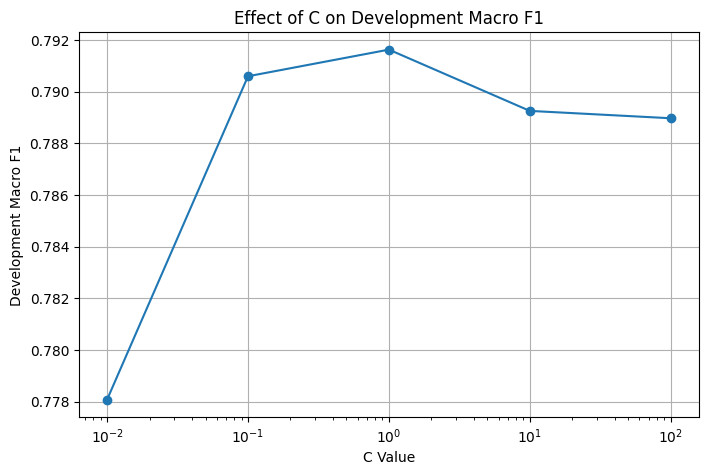

In [ ]:
import matplotlib.pyplot as plt

C_values = [0.01, 0.1, 1, 10, 100]
c_scores = []

for C in C_values:
    temp_model = LogisticRegression(
        C=C,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )

    temp_model.fit(X_train_emb, y_train)

    predictions = temp_model.predict(X_dev_emb)

    score = f1_score(
        y_dev,
        predictions,
        average="macro"
    )

    c_scores.append(score)

# Plot C vs Macro F1
plt.figure(figsize=(8, 5))
plt.plot(C_values, c_scores, marker="o")
plt.xscale("log")
plt.xlabel("C Value")
plt.ylabel("Development Macro F1")
plt.title("Effect of C on Development Macro F1")
plt.grid(True)
plt.show()

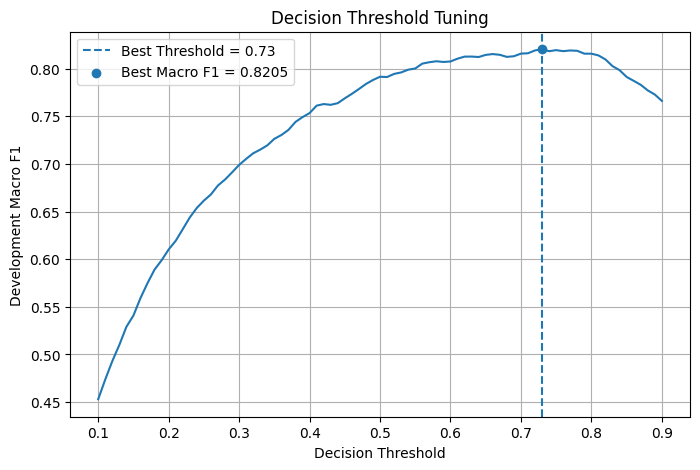

In [ ]:
thresholds = np.arange(0.10, 0.91, 0.01)
threshold_scores = []

dev_probabilities = best_model.predict_proba(X_dev_emb)[:, 1]

for threshold in thresholds:
    predictions = (dev_probabilities >= threshold).astype(int)

    score = f1_score(
        y_dev,
        predictions,
        average="macro"
    )

    threshold_scores.append(score)

# Plot Threshold vs Macro F1
plt.figure(figsize=(8, 5))
plt.plot(thresholds, threshold_scores)
plt.axvline(
    x=best_threshold,
    linestyle="--",
    label=f"Best Threshold = {best_threshold:.2f}"
)
plt.scatter(
    best_threshold,
    best_threshold_f1,
    zorder=3,
    label=f"Best Macro F1 = {best_threshold_f1:.4f}"
)
plt.xlabel("Decision Threshold")
plt.ylabel("Development Macro F1")
plt.title("Decision Threshold Tuning")
plt.legend()
plt.grid(True)
plt.show()

## 9. Model Evaluation (Accuracy, Macro F1, Confusion Matrix)

**Purpose:** Evaluate both final models **once** on the **same test set**.

**Metrics**
- **Accuracy** – overall % correct. Can be misleading when classes are imbalanced.
- **Macro F1** – average F1 of both classes, treating them equally. **Main metric** for this project.
- **Confusion Matrix** – shows TP, TN, FP, FN. False negatives (missed aid requests) are especially costly in disaster response.


In [ ]:
# Import libraries
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [ ]:
# TODO: Define a reusable evaluation function

def evaluate(y_true, y_pred, name):

    # Calculate Accuracy
    accuracy = accuracy_score(y_true, y_pred)

    # Calculate Macro F1
    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro"
    )

    # Print evaluation results
    print(f"\n{name}")
    print("-" * 40)
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")

    # Display Classification Report
    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        target_names=["No Request", "Request for Aid"]
    ))

    return {
        "Method": name,
        "Accuracy": accuracy,
        "Macro F1": macro_f1
    }

In [ ]:
# TODO: Evaluate Method 1 (TF-IDF) on the test set
tfidf_test_prob = tfidf_best_model.predict_proba(X_test_tfidf)[:, 1]
tfidf_test_predictions = (tfidf_test_prob >= tfidf_best_threshold).astype(int)
tfidf_results = evaluate(y_test_tfidf, tfidf_test_predictions,
                         "TF-IDF + Logistic Regression")
tfidf_results["Request Precision"] = precision_score(y_test_tfidf, tfidf_test_predictions, pos_label=1, zero_division=0)
tfidf_results["Request Recall"] = recall_score(y_test_tfidf, tfidf_test_predictions, pos_label=1, zero_division=0)
print(f"Request Precision: {tfidf_results['Request Precision']:.4f}")
print(f"Request Recall:    {tfidf_results['Request Recall']:.4f}")


TF-IDF + Logistic Regression
----------------------------------------
Accuracy: 0.9128
Macro F1: 0.8358

Classification Report:
                 precision    recall  f1-score   support

     No Request       0.93      0.96      0.95      2170
Request for Aid       0.79      0.67      0.72       446

       accuracy                           0.91      2616
      macro avg       0.86      0.82      0.84      2616
   weighted avg       0.91      0.91      0.91      2616

Request Precision: 0.7884
Request Recall:    0.6682


In [ ]:
# TODO: Evaluate Method 2 (SBERT) on the test set

# Get predicted probabilities
test_probabilities = best_model.predict_proba(X_test_emb)[:, 1]

# Apply the tuned decision threshold
test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

# Evaluate SBERT
sbert_results = evaluate(
    y_test,
    test_predictions,
    "Sentence-BERT + Logistic Regression"
)


Sentence-BERT + Logistic Regression
----------------------------------------
Accuracy: 0.9083
Macro F1: 0.8336

Classification Report:
                 precision    recall  f1-score   support

     No Request       0.94      0.95      0.95      2170
Request for Aid       0.75      0.70      0.72       446

       accuracy                           0.91      2616
      macro avg       0.84      0.83      0.83      2616
   weighted avg       0.91      0.91      0.91      2616



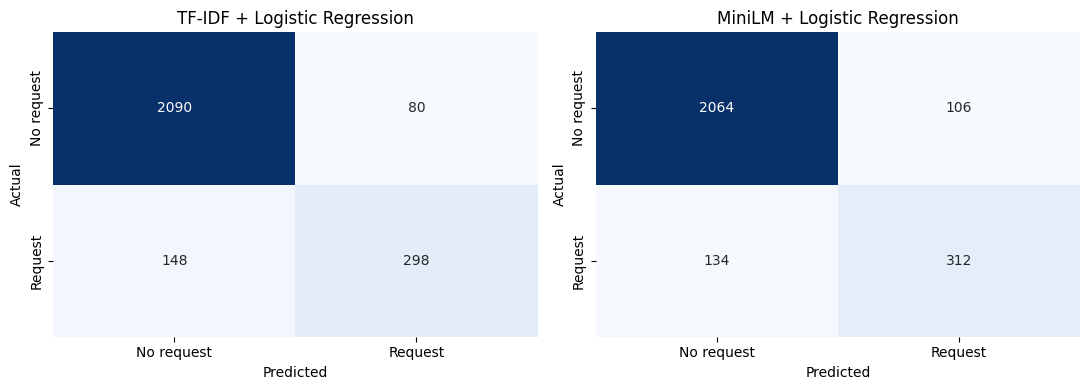

In [ ]:
# TODO: Plot both confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pred, title in zip(axes,
                           [tfidf_test_predictions, test_predictions],
                           ["TF-IDF + Logistic Regression", "MiniLM + Logistic Regression"]):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No request", "Request"],
                yticklabels=["No request", "Request"])
    ax.set(title=title, xlabel="Predicted", ylabel="Actual")
plt.tight_layout(); plt.show()

In [ ]:
# TODO: Create a results summary table (Method | Accuracy | Macro F1)
sbert_results["Request Precision"] = precision_score(y_test, test_predictions, pos_label=1, zero_division=0)
sbert_results["Request Recall"] = recall_score(y_test, test_predictions, pos_label=1, zero_division=0)
comparison_df = pd.DataFrame([tfidf_results, sbert_results])
display(comparison_df.round(4))
comparison_df.to_csv("model_comparison_results.csv", index=False)
print("Saved model_comparison_results.csv")

if "genre" in test_df.columns:
    mask = test_df["genre"].eq("direct").to_numpy()
    if mask.sum() >= 20 and len(np.unique(y_test[mask])) == 2:
        direct_scores = pd.DataFrame([
            {"Method": "TF-IDF", "N": int(mask.sum()),
             "Accuracy": accuracy_score(y_test[mask], tfidf_test_predictions[mask]),
             "Macro F1": f1_score(y_test[mask], tfidf_test_predictions[mask], average="macro"),
             "Request Precision": precision_score(y_test[mask], tfidf_test_predictions[mask], zero_division=0),
             "Request Recall": recall_score(y_test[mask], tfidf_test_predictions[mask], zero_division=0)},
            {"Method": "Sentence-BERT", "N": int(mask.sum()),
             "Accuracy": accuracy_score(y_test[mask], test_predictions[mask]),
             "Macro F1": f1_score(y_test[mask], test_predictions[mask], average="macro"),
             "Request Precision": precision_score(y_test[mask], test_predictions[mask], zero_division=0),
             "Request Recall": recall_score(y_test[mask], test_predictions[mask], zero_division=0)}
        ])
        print("Direct-message subgroup (descriptive only):"); display(direct_scores.round(4))
    else:
        print("Too few direct messages or insufficient class coverage for a subgroup comparison.")

,Method,Accuracy,Macro F1,Request Precision,Request Recall
0,TF-IDF + Logistic Regression,0.9128,0.8358,0.7884,0.6682
1,Sentence-BERT + Logistic Regression,0.9083,0.8336,0.7464,0.6996


Saved model_comparison_results.csv
Direct-message subgroup (descriptive only):


,Method,N,Accuracy,Macro F1,Request Precision,Request Recall
0,TF-IDF,1055,0.8626,0.8475,0.8073,0.7918
1,Sentence-BERT,1055,0.8483,0.8343,0.7676,0.8055


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


## 10. Error Analysis & Model Comparison

**Purpose:** Go beyond the numbers — understand *where* and *why* each model fails.


In [ ]:
# TODO: Extract and display false positives / false negatives for each method
error_table = test_df[[TEXT_COL, TARGET_COL]].reset_index(drop=True).copy()
error_table["TF-IDF prediction"] = tfidf_test_predictions
error_table["SBERT prediction"] = test_predictions
for method, column in [("TF-IDF", "TF-IDF prediction"), ("SBERT", "SBERT prediction")]:
    for error_type, actual, predicted in [("False positive", 0, 1), ("False negative", 1, 0)]:
        subset = error_table[(error_table[TARGET_COL] == actual) & (error_table[column] == predicted)]
        print(f"{method} / {error_type}: {len(subset)} errors")

TF-IDF / False positive: 80 errors
TF-IDF / False negative: 148 errors
SBERT / False positive: 106 errors
SBERT / False negative: 134 errors


In [ ]:
# TODO: Find and display messages where the two methods disagree
different = error_table[error_table["TF-IDF prediction"] != error_table["SBERT prediction"]]
print("Models disagree on", len(different), "test messages")
display(different.head(10))

Models disagree on 188 test messages


,message,request,TF-IDF prediction,SBERT prediction
6,RT compassion Donate to the Disaster Relief Fu...,0,1,0
33,"Please HELP, were survirors living the city of...",1,1,0
37,We can work as possible must be immediately te...,0,0,1
49,We do not have food or money. We will go to ou...,1,0,1
54,I want to have food each day. I live in Matiss...,1,0,1
60,"I can offer food supplies , blankets , etc .",0,0,1
94,"We are treating cases of extreme exhaustion, d...",0,0,1
98,We are starting a collection up here in the se...,0,0,1
100,"I am from to croix-des-bouquets,thanks for you...",0,1,0
101,"Even in Moghav we've asked for aid, we are wri...",1,0,1


In [ ]:
# TODO: Show top TF-IDF features (Logistic Regression coefficients)
feature_names = tfidf_vectorizer.get_feature_names_out()
coefs = tfidf_best_model.coef_[0]
top_positive = np.argsort(coefs)[-15:][::-1]
top_negative = np.argsort(coefs)[:15]
print("Features favoring aid requests:", list(zip(feature_names[top_positive], np.round(coefs[top_positive], 3))))
print("Features favoring no request:", list(zip(feature_names[top_negative], np.round(coefs[top_negative], 3))))

Features favoring aid requests: [('help', np.float64(13.677)), ('need', np.float64(11.676)), ('tent', np.float64(9.41)), ('hungry', np.float64(8.613)), ('food', np.float64(8.46)), ('aid', np.float64(8.193)), ('tents', np.float64(7.84)), ('water', np.float64(7.804)), ('shelter', np.float64(7.802)), ('hunger', np.float64(7.394)), ('needed', np.float64(6.969)), ('we', np.float64(6.762)), ('us', np.float64(6.64)), ('needs', np.float64(6.613)), ('victim', np.float64(6.155))]
Features favoring no request: [('job', np.float64(-8.484)), ('news', np.float64(-5.043)), ('work', np.float64(-4.308)), ('love', np.float64(-4.012)), ('can donate', np.float64(-3.968)), ('including', np.float64(-3.757)), ('santiago', np.float64(-3.704)), ('items', np.float64(-3.625)), ('office', np.float64(-3.624)), ('food card', np.float64(-3.605)), ('were', np.float64(-3.595)), ('need job', np.float64(-3.555)), ('each', np.float64(-3.529)), ('development', np.float64(-3.43)), ('reached', np.float64(-3.412))]


## 11. Predict New Messages

**Purpose:** Demonstrate both models on new, unseen messages.



In [ ]:
# TODO: Define predict_message() using both trained models
def predict_message(text):
    if not isinstance(text, str) or not text.strip():
        print("Please enter a non-empty disaster-related message.")
        return None
    cleaned = clean_text(text)
    if not cleaned:
        print("Please enter a message containing English words.")
        return None
    tfidf_prob = float(tfidf_best_model.predict_proba(tfidf_vectorizer.transform([cleaned]))[0, 1])
    embedding = sbert.encode([light_clean(text)], convert_to_numpy=True)
    sbert_prob = float(best_model.predict_proba(embedding)[0, 1])
    result = {"Message": text,
              "TF-IDF": LABEL_NAMES[int(tfidf_prob >= tfidf_best_threshold)],
              "TF-IDF P(request)": round(tfidf_prob, 4),
              "Sentence-BERT": LABEL_NAMES[int(sbert_prob >= best_threshold)],
              "Sentence-BERT P(request)": round(sbert_prob, 4)}
    display(pd.DataFrame([result])); return result


predict_message("We need clean drinking water in our neighborhood, please help.")

,Message,TF-IDF,TF-IDF P(request),Sentence-BERT,Sentence-BERT P(request)
0,We need clean drinking water in our neighborho...,Request for Aid,0.9986,Request for Aid,0.8893


{'Message': 'We need clean drinking water in our neighborhood, please help.',
 'TF-IDF': 'Request for Aid',
 'TF-IDF P(request)': 0.9986,
 'Sentence-BERT': 'Request for Aid',
 'Sentence-BERT P(request)': 0.8893}

In [ ]:
# TODO: Test the function on a list of example messages you write
example_messages = [
    ("We are trapped in our house after the flood. Please send a rescue team.", 1),
    ("Our community needs clean drinking water and food supplies.", 1),
    ("Please provide temporary shelter for families who lost their homes.", 1),
    ("The rescue teams arrived in the flooded city yesterday.", 0),
    ("Volunteers distributed food and water to affected families.", 0),
    ("The government announced updates about the earthquake damage.", 0)
]

# To run the trained models on every example.
for message, expected_label in example_messages:
    print("=" * 60)
    print("Expected:", "Aid Request" if expected_label == 1 else "No Aid Request")
    predict_message(message)

Expected: Aid Request


,Message,TF-IDF,TF-IDF P(request),Sentence-BERT,Sentence-BERT P(request)
0,We are trapped in our house after the flood. P...,Request for Aid,0.9809,Request for Aid,0.9944


Expected: Aid Request


,Message,TF-IDF,TF-IDF P(request),Sentence-BERT,Sentence-BERT P(request)
0,Our community needs clean drinking water and f...,Request for Aid,0.771,Request for Aid,0.8383


Expected: Aid Request


,Message,TF-IDF,TF-IDF P(request),Sentence-BERT,Sentence-BERT P(request)
0,Please provide temporary shelter for families ...,Request for Aid,0.7495,Request for Aid,0.9724


... (2 outputs left out)

Expected: No Aid Request


,Message,TF-IDF,TF-IDF P(request),Sentence-BERT,Sentence-BERT P(request)
0,Volunteers distributed food and water to affec...,Request for Aid,0.8626,Request for Aid,0.7628


Expected: No Aid Request


,Message,TF-IDF,TF-IDF P(request),Sentence-BERT,Sentence-BERT P(request)
0,The government announced updates about the ear...,No Request,0.1012,No Request,0.0789


## 12. Conclusion & References

### Conclusion
The following points highlight the main findings,Trade-offs, limitations, and future work of this study.
- **Answer to the experimental question:** TF-IDF slightly outperformed the SBERT method with 0.9128 accuracy and 0.8358 Macro-F1 score. While SBERT achieved 0.9083 accuracy and 0.8336 Macro-F1 score.
- **Key findings**TF-IDF achieved higher precision, while SBERT achieved higher recall for the aid request class. The error analysis section showed that TF-IDF had fewer false positives (80 versus 106), while SBERT had fewer false negatives (134 versus 148).
- **Trade-offs:** TF-IDF is easier and simpler to implement,while SBERT can capture the contextual meaning of the messages better but requires more resources.
- **Limitations:** The models were traiend only on an English-language dataset and it contained a class imbalance.
- **Future work:** Model performance could be optimized using several text representation techniques and classifiers.Additionally the models could be trained with diverse disaster-related messages in additional languages.

### References
[1] Figure Eight, “Disaster Response Messages,” Kaggle. Available: https://www.kaggle.com/datasets/sidharth178/disaster-response-messages

[2] N. Reimers and I. Gurevych, “Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks,” in *Proc. EMNLP-IJCNLP*, 2019.

[3] Scikit-learn, “Sklearn.Model_Selection.Train_Test_Split — Scikit-Learn 0.20.3 Documentation,” Scikit-learn.org, 2018. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html (accessed Nov. 14, 2026).

[4] Scikit-learn, “Sklearn.Model_Selection.Train_Test_Split — Scikit-Learn 0.20.3 Documentation,” Scikit-learn.org, 2018. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html (accessed Nov. 14, 2026).

[5] Scikit-learn, “Sklearn.Metrics.ConfusionMatrixDisplay,” scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html (accessed Nov. 14, 2026).

[6] Scikit-learn, “LogisticRegression,” Scikit-learn.org, 2014. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html (accessed Nov. 14, 2026).

[7] Scikit learn, “TfidfVectorizer,” Scikit-learn.org, 2018. https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html (accessed Nov. 14, 2026).